In [31]:
!pip install xgboost shap imbalanced-learn -q

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
print(df.shape)

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition (2).csv
(1470, 35)


In [33]:
print(df["Attrition"].value_counts())
print(df.isnull().sum().sum(), "missing values")
df.head()

Attrition
No     1233
Yes     237
Name: count, dtype: int64
0 missing values


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df_clean = df.drop(["EmployeeNumber", "EmployeeCount", "Over18", "StandardHours"], axis=1)
df_clean["Attrition"] = df_clean["Attrition"].map({"Yes": 1, "No": 0})
df_clean = pd.get_dummies(df_clean, drop_first=True)

X = df_clean.drop("Attrition", axis=1)
y = df_clean["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Attrition rate in train:", y_train.mean().round(3))

Train: (1176, 44) Test: (294, 44)
Attrition rate in train: 0.162


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
xgb = XGBClassifier(scale_pos_weight=5, eval_metric="logloss", random_state=42)

lr.fit(X_train_sc, y_train)
rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)
print("All 3 models trained")

All 3 models trained


In [36]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

preds = {
    "Logistic Regression": (lr, X_test_sc),
    "Random Forest": (rf, X_test),
    "XGBoost": (xgb, X_test),
}

results = []
for name, (model, Xt) in preds.items():
    y_pred = model.predict(Xt)
    y_prob = model.predict_proba(Xt)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.752,0.345,0.617,0.443,0.798
1,Random Forest,0.837,0.444,0.085,0.143,0.771
2,XGBoost,0.854,0.571,0.340,0.427,0.751


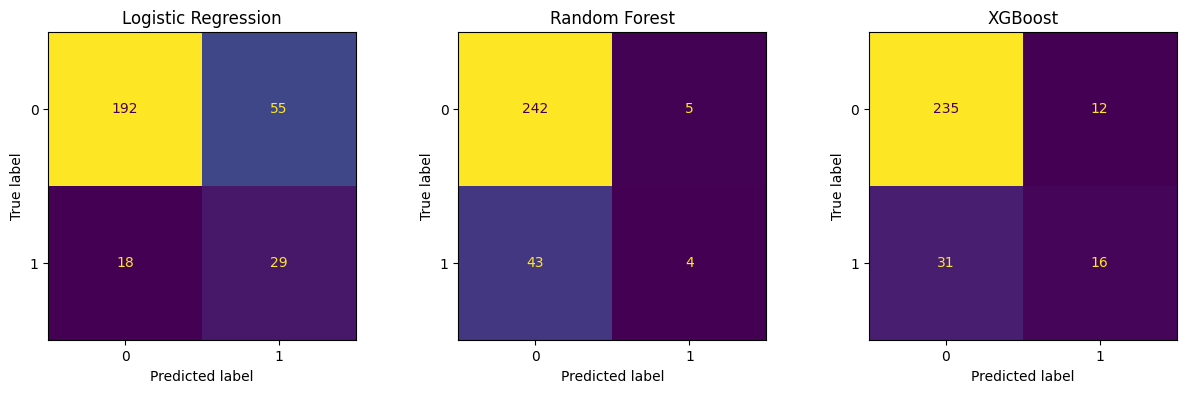

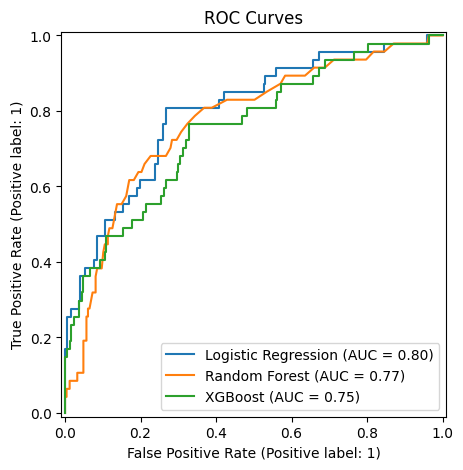

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (model, Xt)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_estimator(model, Xt, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, (model, Xt) in preds.items():
    RocCurveDisplay.from_estimator(model, Xt, y_test, ax=ax, name=name)
plt.title("ROC Curves")
plt.show()

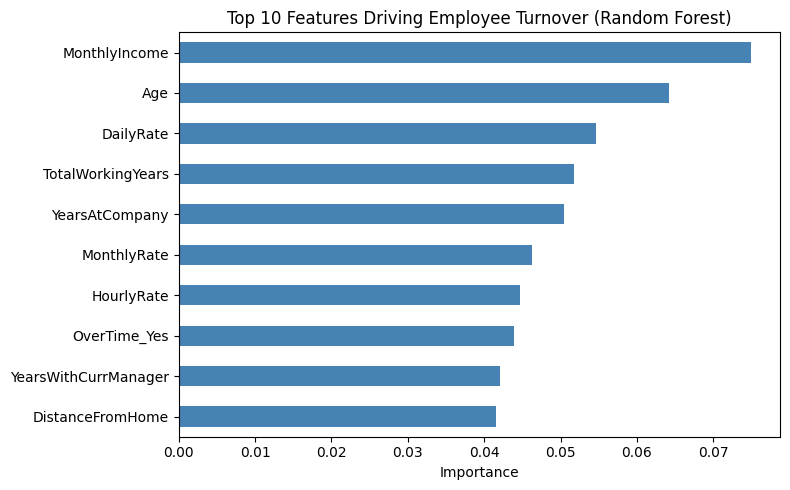

MonthlyIncome           0.075
Age                     0.064
DailyRate               0.055
TotalWorkingYears       0.052
YearsAtCompany          0.051
MonthlyRate             0.046
HourlyRate              0.045
OverTime_Yes            0.044
YearsWithCurrManager    0.042
DistanceFromHome        0.042
dtype: float64


In [38]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Features Driving Employee Turnover (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(top10.round(3))

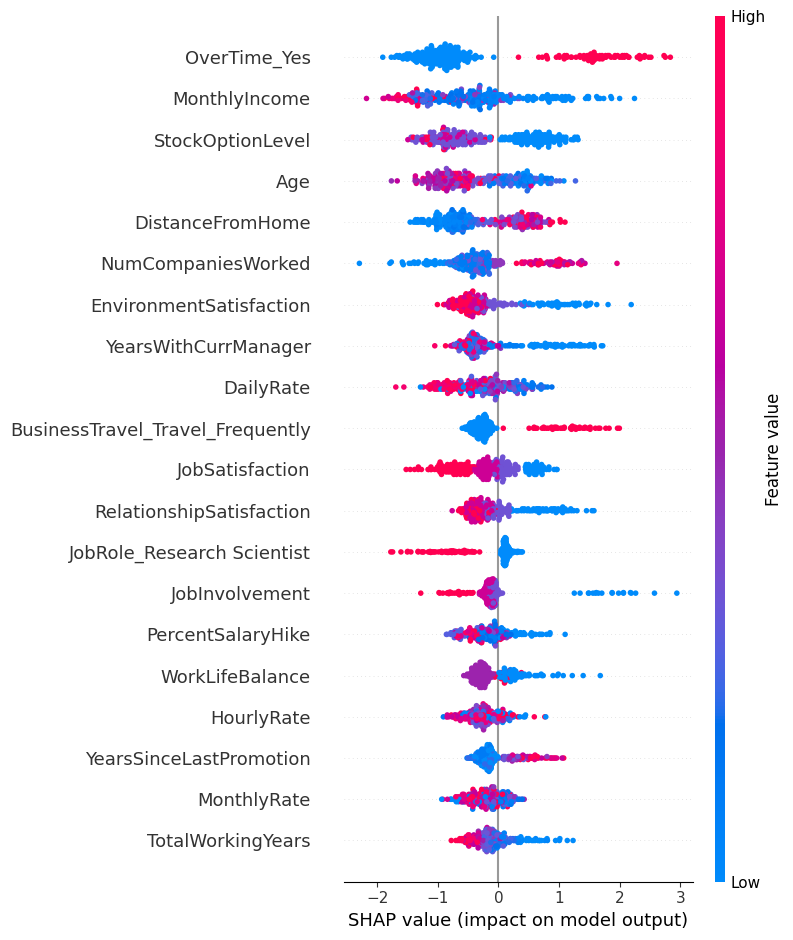

In [39]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=True)

In [40]:
from sklearn.model_selection import cross_val_score

for name, model, Xd in [("Random Forest", rf, X), ("XGBoost", xgb, X)]:
    scores = cross_val_score(model, Xd, y, cv=5, scoring="roc_auc")
    print(name, "5-fold AUC:", scores.mean().round(3), "+/-", scores.std().round(3))

Random Forest 5-fold AUC: 0.8 +/- 0.03
XGBoost 5-fold AUC: 0.806 +/- 0.028


In [41]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, roc_auc_score
from xgboost import XGBClassifier

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "scale_pos_weight": [3, 5, 6],
}

search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", random_state=42),
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1,
)

search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)

best = search.best_estimator_
y_pred = best.predict(X_test)

print(classification_report(y_test, y_pred))
print("Tuned AUC:", round(roc_auc_score(y_test, best.predict_proba(X_test)[:, 1]), 3))

Best parameters: {'subsample': 0.7, 'scale_pos_weight': 3, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05}
              precision    recall  f1-score   support

           0       0.88      0.96      0.92       247
           1       0.61      0.30      0.40        47

    accuracy                           0.86       294
   macro avg       0.74      0.63      0.66       294
weighted avg       0.84      0.86      0.84       294

Tuned AUC: 0.783


In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

final_models = {
    "Logistic Regression": (lr, X_test_sc),
    "Random Forest": (rf, X_test),
    "XGBoost": (xgb, X_test),
    "XGBoost (Tuned)": (best, X_test),
}

rows = []
for name, (model, Xt) in final_models.items():
    yp = model.predict(Xt)
    ypr = model.predict_proba(Xt)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, yp),
        "Precision": precision_score(y_test, yp),
        "Recall": recall_score(y_test, yp),
        "F1": f1_score(y_test, yp),
        "ROC-AUC": roc_auc_score(y_test, ypr),
    })

final_df = pd.DataFrame(rows).round(3)
final_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.752,0.345,0.617,0.443,0.798
1,Random Forest,0.837,0.444,0.085,0.143,0.771
2,XGBoost,0.854,0.571,0.340,0.427,0.751
3,XGBoost (Tuned),0.857,0.609,0.298,0.400,0.783


In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

dt = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
knn = KNeighborsClassifier(n_neighbors=5)
svm = SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42)

dt.fit(X_train, y_train)
knn.fit(X_train_sc, y_train)
svm.fit(X_train_sc, y_train)

all_models = {
    "Logistic Regression": (lr, X_test_sc),
    "Decision Tree": (dt, X_test),
    "KNN": (knn, X_test_sc),
    "SVM": (svm, X_test_sc),
    "Random Forest": (rf, X_test),
    "XGBoost": (xgb, X_test),
    "XGBoost (Tuned)": (best, X_test),
}

rows = []
for name, (model, Xt) in all_models.items():
    yp = model.predict(Xt)
    ypr = model.predict_proba(Xt)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, yp),
        "Precision": precision_score(y_test, yp, zero_division=0),
        "Recall": recall_score(y_test, yp),
        "F1": f1_score(y_test, yp),
        "ROC-AUC": roc_auc_score(y_test, ypr),
    })

pd.DataFrame(rows).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.752,0.345,0.617,0.443,0.798
1,Decision Tree,0.772,0.357,0.532,0.427,0.652
2,KNN,0.847,0.625,0.106,0.182,0.636
3,SVM,0.820,0.446,0.532,0.485,0.790
4,Random Forest,0.837,0.444,0.085,0.143,0.771
5,XGBoost,0.854,0.571,0.340,0.427,0.751
6,XGBoost (Tuned),0.857,0.609,0.298,0.400,0.783


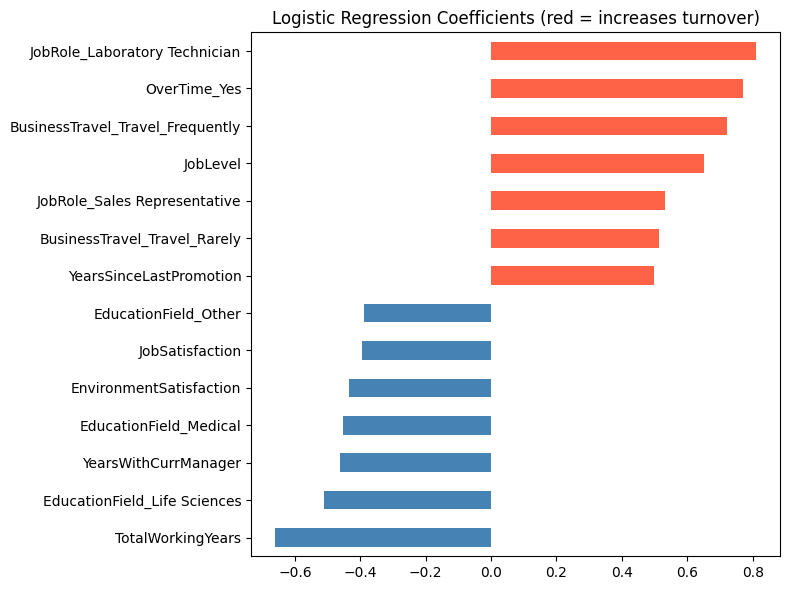

In [44]:
coef = pd.Series(lr.coef_[0], index=X_train.columns).sort_values()
top = pd.concat([coef.head(7), coef.tail(7)])

plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["tomato" if v > 0 else "steelblue" for v in top])
plt.title("Logistic Regression Coefficients (red = increases turnover)")
plt.tight_layout()
plt.show()

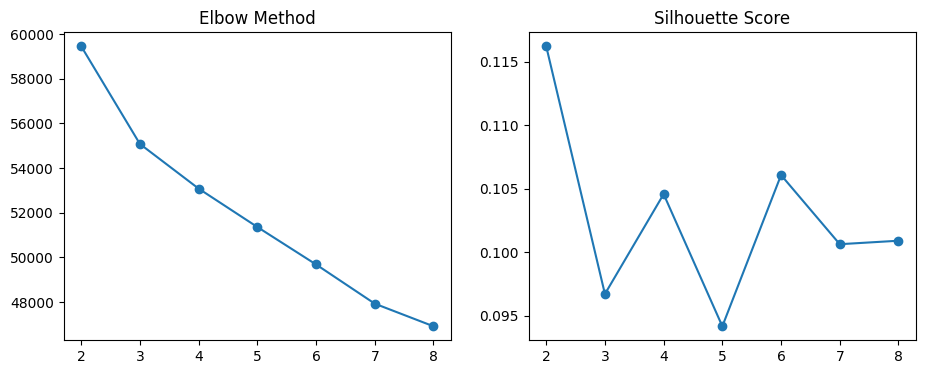

Attrition rate per cluster:
Cluster
0    0.165
1    0.221
2    0.056
Name: Attrition, dtype: float64

Average values per cluster:
          Age  MonthlyIncome  YearsAtCompany
Cluster                                     
0        35.0         4178.8             5.3
1        35.2         5912.0             6.1
2        46.0        15035.0            14.0


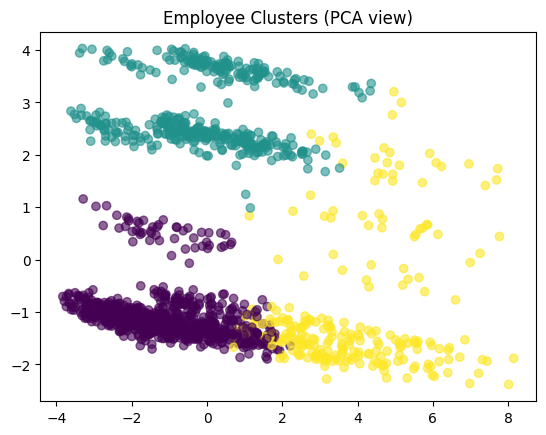

In [56]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Scale the features (needed for clustering)
X_scaled = StandardScaler().fit_transform(X)

# Find the best number of clusters
inertia, sil = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow Method")
ax[1].plot(ks, sil, marker="o"); ax[1].set_title("Silhouette Score")
plt.show()

# Final clustering with 3 groups
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)
df["Cluster"] = km.labels_

print("Attrition rate per cluster:")
print(df.groupby("Cluster")["Attrition"].apply(lambda s: (s == "Yes").mean()).round(3))

print("\nAverage values per cluster:")
print(df.groupby("Cluster")[["Age", "MonthlyIncome", "YearsAtCompany"]].mean().round(1))

# Plot the clusters in 2D
pts = PCA(n_components=2).fit_transform(X_scaled)
plt.scatter(pts[:, 0], pts[:, 1], c=km.labels_, cmap="viridis", alpha=0.6)
plt.title("Employee Clusters (PCA view)")
plt.show()

In [57]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cands = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Decision Tree (CART)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
}

rows = []
for name, m in cands.items():
    s = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "recall", "f1", "roc_auc"])
    rows.append({"Model": name,
                 "Accuracy": s["test_accuracy"].mean(),
                 "Recall": s["test_recall"].mean(),
                 "F1": s["test_f1"].mean(),
                 "ROC-AUC": s["test_roc_auc"].mean()})
pd.DataFrame(rows).round(3)

,Model,Accuracy,Recall,F1,ROC-AUC
0,Logistic Regression,0.754,0.713,0.483,0.824
1,Decision Tree (CART),0.780,0.595,0.467,0.734
2,Naive Bayes,0.756,0.637,0.458,0.765
3,Random Forest,0.854,0.118,0.204,0.801


In [51]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score

nb = GaussianNB()
nb.fit(X_train, y_train)

summary = {
    "Logistic Regression": (lr, X_test_sc),
    "Decision Tree (CART)": (dt, X_test),
    "Naive Bayes": (nb, X_test),
    "Random Forest": (rf, X_test),
}

print("Baseline (predict everyone stays):", round(1 - y_test.mean(), 3))
print()
for name, (m, Xt) in summary.items():
    p = m.predict(Xt)
    print(f"{name:22s} Accuracy={accuracy_score(y_test, p):.3f}  "
          f"Recall={recall_score(y_test, p):.3f}  "
          f"AUC={roc_auc_score(y_test, m.predict_proba(Xt)[:, 1]):.3f}")

Baseline (predict everyone stays): 0.84

Logistic Regression    Accuracy=0.752  Recall=0.617  AUC=0.798
Decision Tree (CART)   Accuracy=0.772  Recall=0.532  AUC=0.652
Naive Bayes            Accuracy=0.721  Recall=0.617  AUC=0.726
Random Forest          Accuracy=0.837  Recall=0.085  AUC=0.771


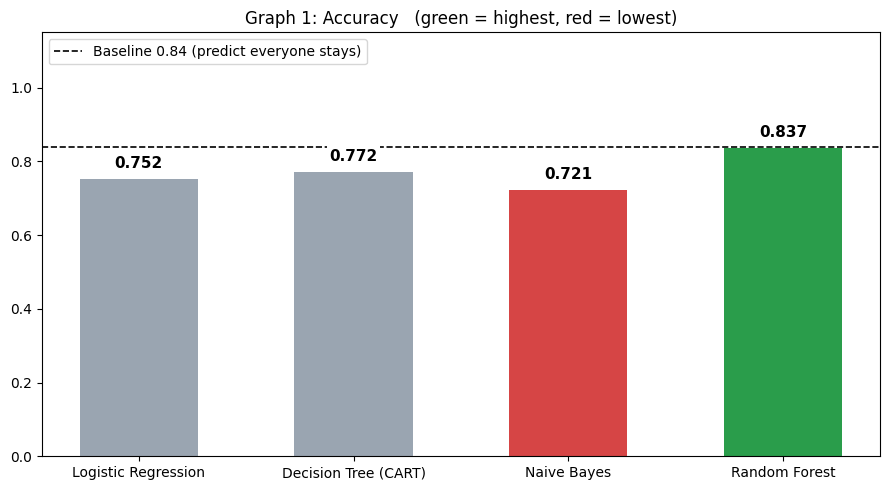

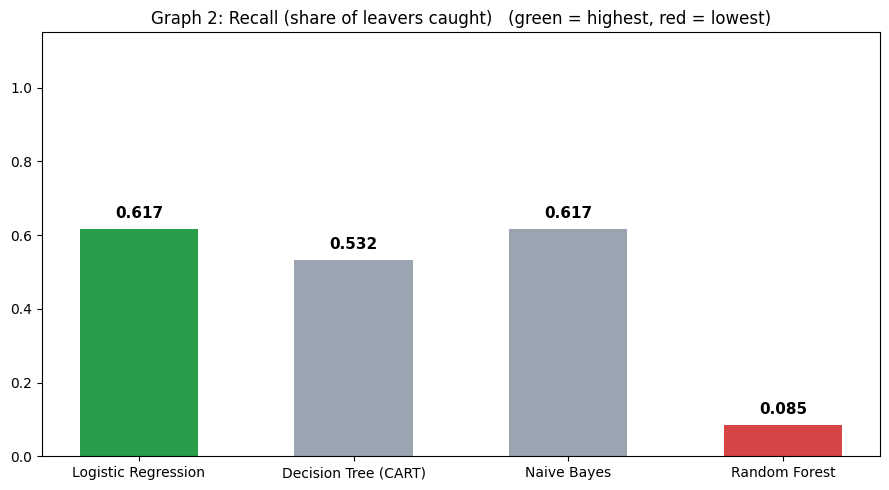

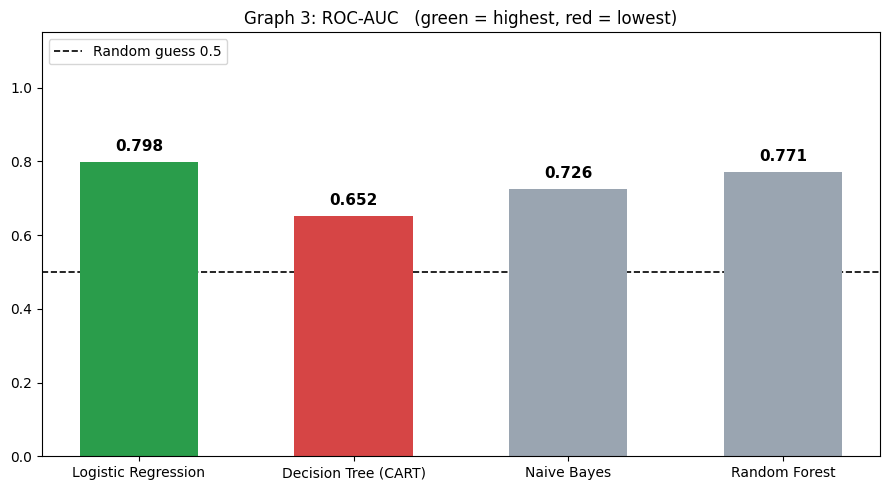

In [54]:
import matplotlib.pyplot as plt
import numpy as np

names    = ["Logistic Regression", "Decision Tree (CART)", "Naive Bayes", "Random Forest"]
accuracy = [0.752, 0.772, 0.721, 0.837]
recall   = [0.617, 0.532, 0.617, 0.085]
auc      = [0.798, 0.652, 0.726, 0.771]
baseline = 0.84

def bar_colors(values):
    c = ["#9aa5b1"] * len(values)          # grey = middle
    c[int(np.argmax(values))] = "#2a9d4b"  # green = highest
    c[int(np.argmin(values))] = "#d64545"  # red = lowest
    return c

def draw(values, title, line=None, line_label=None):
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(names, values, color=bar_colors(values), width=0.55, zorder=2)
    if line is not None:
        ax.axhline(line, color="black", linestyle="--", linewidth=1.2, label=line_label, zorder=1)
        ax.legend(loc="upper left", fontsize=10)
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.3f}",
                ha="center", fontsize=11, fontweight="bold",
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=3)
    ax.set_ylim(0, 1.15)
    ax.set_title(title + "   (green = highest, red = lowest)", fontsize=12)
    ax.tick_params(axis="x", labelsize=10)
    plt.tight_layout()
    plt.show()

draw(accuracy, "Graph 1: Accuracy", baseline, "Baseline 0.84 (predict everyone stays)")
draw(recall,   "Graph 2: Recall (share of leavers caught)")
draw(auc,      "Graph 3: ROC-AUC", 0.5, "Random guess 0.5")

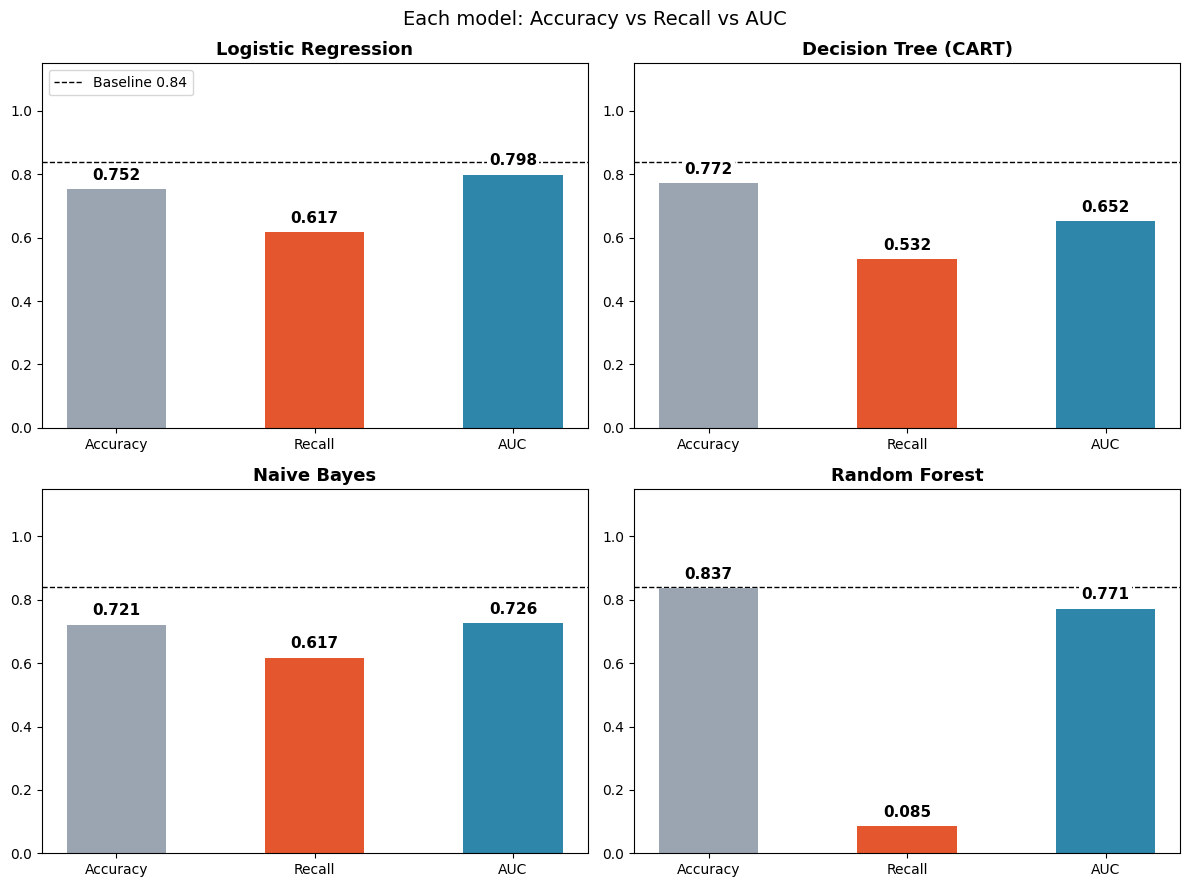

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
metrics = ["Accuracy", "Recall", "AUC"]
bar_cols = ["#9aa5b1", "#e4572e", "#2e86ab"]

for i, ax in enumerate(axes.flatten()):
    vals = [accuracy[i], recall[i], auc[i]]
    bars = ax.bar(metrics, vals, color=bar_cols, width=0.5, zorder=2)
    ax.axhline(baseline, color="black", linestyle="--", linewidth=1, zorder=1,
               label="Baseline 0.84" if i == 0 else None)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.3f}",
                ha="center", fontsize=11, fontweight="bold",
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=3)
    ax.set_ylim(0, 1.15)
    ax.set_title(names[i], fontsize=13, fontweight="bold")

axes[0, 0].legend(loc="upper left", fontsize=10)
plt.suptitle("Each model: Accuracy vs Recall vs AUC", fontsize=14)
plt.tight_layout()
plt.show()